# Question 2: Weather and respond rates

With this part of the report we intend to explore how we can extend the existing data set by performing data integration. 

We discussed in which ways we can integrate new data in a meaningful way and decided to take point 
of departure in the timestamp of the specific responses to the survey (a row). We integrated one new data point and engineered another one: 

1. Daily accumulated precip (integrated with the DMI's Open Data API). 
2. Number of entries per day.

These two new data points allow us to investigate if there is a correlation between the amount of rain (accumulated precip) and the number of daily survey responses.

**Hypothesis:** On a rainy day a student is more likely to fill out the survey since they cannot go the beach

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("../Cleaned/dataminers_cleaner.csv")
df["timestamp_cph"] = pd.to_datetime(df["timestamp_cph"])
daily = df["timestamp_cph"].dt.date.value_counts().sort_index()

## Visualizing the number of entries per day

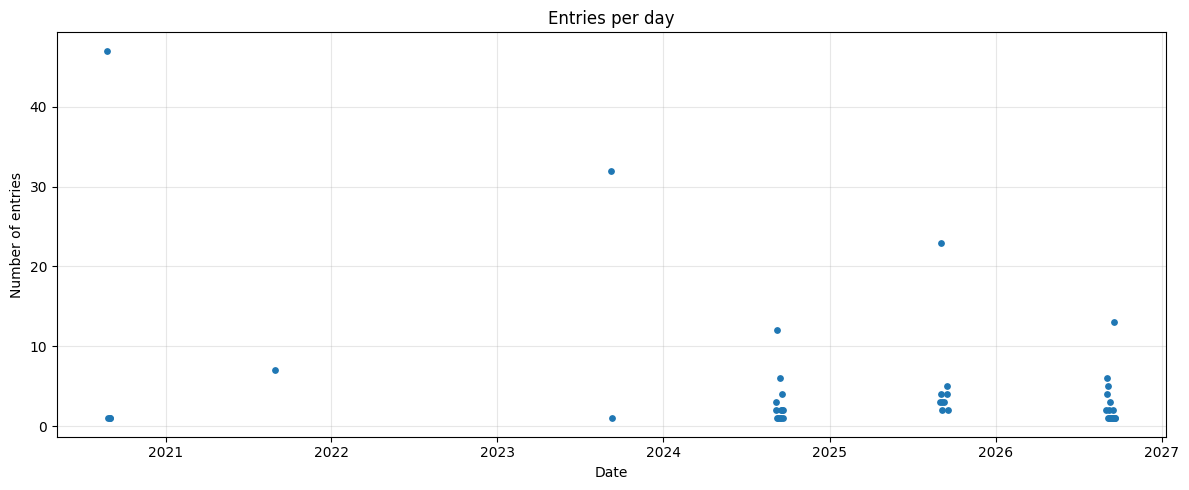

In [25]:
plt.figure(figsize=(12, 5))
plt.scatter(daily.index, daily.values, s=15)
plt.xlabel("Date")
plt.ylabel("Number of entries")
plt.title("Entries per day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Creating a record of the dates and the number of entries on that given day:

In [ ]:
daily_entries = [
    {"date": date, "entries": int(count)}
    for date, count in daily.items()
]

for i in daily_entries:
    print(i)

#Storing it to rainfall data file:
out = pd.DataFrame(daily_entries).sort_values("date")
out.to_csv("daily_entries.csv", index = False)

{'date': datetime.date(2020, 8, 26), 'entries': 47}
{'date': datetime.date(2020, 8, 27), 'entries': 1}
{'date': datetime.date(2020, 9, 1), 'entries': 1}
{'date': datetime.date(2020, 9, 2), 'entries': 1}
{'date': datetime.date(2021, 8, 30), 'entries': 7}
{'date': datetime.date(2023, 9, 7), 'entries': 32}
{'date': datetime.date(2023, 9, 10), 'entries': 1}
{'date': datetime.date(2024, 9, 4), 'entries': 2}
{'date': datetime.date(2024, 9, 5), 'entries': 3}
{'date': datetime.date(2024, 9, 6), 'entries': 12}
{'date': datetime.date(2024, 9, 7), 'entries': 1}
{'date': datetime.date(2024, 9, 8), 'entries': 1}
{'date': datetime.date(2024, 9, 13), 'entries': 6}
{'date': datetime.date(2024, 9, 14), 'entries': 1}
{'date': datetime.date(2024, 9, 15), 'entries': 1}
{'date': datetime.date(2024, 9, 16), 'entries': 2}
{'date': datetime.date(2024, 9, 17), 'entries': 4}
{'date': datetime.date(2024, 9, 18), 'entries': 2}
{'date': datetime.date(2024, 9, 19), 'entries': 1}
{'date': datetime.date(2024, 9, 20),

### Create a record of accumulated precip for each day:

In [15]:
import time
import requests
import pandas as pd

BASE_URL = "https://opendataapi.dmi.dk/v2/climateData/collections/stationValue/items"
STATION_ID = "06180"        # Copenhagen Airport (Kastrup)
PARAMETER = "acc_precip"    # accumulated precipitation, mm
CPH = "Europe/Copenhagen"
FMT = "%Y-%m-%dT%H:%M:%SZ"


def get_daily_rain_mm(date):
    day_start = pd.Timestamp(date).tz_localize(CPH).tz_convert("UTC") 
    day_end = (pd.Timestamp(date) + pd.DateOffset(days=1)).tz_localize(CPH).tz_convert("UTC")

    params = {
        "stationId": STATION_ID,
        "parameterId": PARAMETER,
        "timeResolution": "day",
        "datetime": f"{day_start.strftime(FMT)}/{day_end.strftime(FMT)}",
    }
    r = requests.get(BASE_URL, params=params, timeout=30)
    r.raise_for_status()

    for f in r.json().get("features", []):
        p = f["properties"]
        start = pd.to_datetime(p["from"], utc=True)
        if day_start <= start < day_end: # start included, end excluded (due to the format of DMI)
            return p["value"]
    return None # DMI does not have a value for that day


# Load the date from the clean file
df = pd.read_csv("../Cleaned/dataminers_cleaner.csv", parse_dates=["timestamp_cph"])
dates = sorted(df["timestamp_cph"].dropna().dt.date.unique())

# Fetch rainfall per date
rows = []
for d in dates:
    rows.append({"date": d, "mm_rain": get_daily_rain_mm(d)})
    time.sleep(0.1) #good practise to include pauses when working with API calls

date_rainfall = pd.DataFrame(rows)
date_rainfall.to_csv("../Cleaned/date_rainfall.csv", index=False)

# tests: 
print(f"{len(dates)} unique dates")
print(date_rainfall.head())
print("Missing:", date_rainfall["mm_rain"].isna().sum())

45 unique dates
         date  mm_rain
0  2020-08-26      3.7
1  2020-08-27     11.3
2  2020-09-01      0.5
3  2020-09-02      0.3
4  2021-08-30      0.0
Missing: 0


In [38]:
daily_entries = pd.read_csv("daily_entries.csv", parse_dates=["date"])
daily_rainfall = pd.read_csv("../Cleaned/date_rainfall.csv", parse_dates=["date"])

combined = daily_entries.merge(daily_rainfall, on="date", how="left")
combined = combined.sort_values("date")

combined.to_csv("daily_entries_with_rainfall.csv", index=False)

In [43]:
#linear regression
model = LinearRegression()

df = pd.read_csv("daily_entries_with_rainfall.csv")

X = df[["mm_rain"]]
y = df["entries"]

#splitting into training and test set
X_training, X_test, y_training, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model.fit(X_training, y_training)

#predict values
y_pred = model.predict(X_test)

intercept = model.intercept_
slope = model.coef_[0]
print(f"The linear equation for the correlation between rain and number of entries is: y = {slope:.4f}x + {intercept:.4f} ")

The linear equation for the correlation between rain and number of entries is: y = -0.0817x + 5.5370 


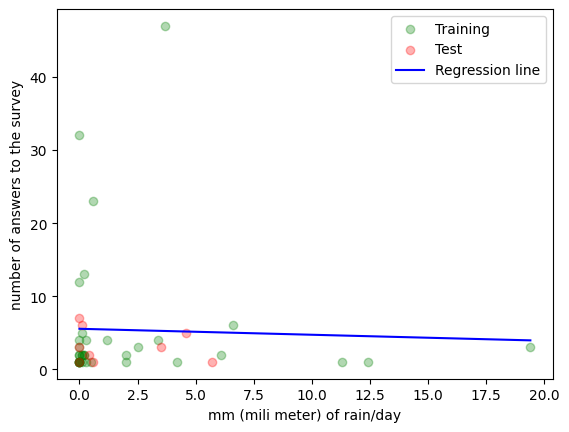

In [46]:
plt.scatter(X_training, y_training, alpha=0.3, color="green", label="Training")
plt.scatter(X_test, y_test, alpha = 0.3, color="red", label="Test")
plt.xlabel("mm (mili meter) of rain/day")
plt.ylabel("number of answers to the survey")
x_line = pd.DataFrame({
    "mm_rain": np.linspace(X["mm_rain"].min(), X["mm_rain"].max(), 100)
})
plt.plot(
    x_line["mm_rain"],
    model.predict(x_line),
    color="blue",
    label="Regression line"
)
plt.legend()
plt.show()

In [54]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2_train = r2_score(y_training, model.predict(X_training))
r2_test = r2_score(y_test, y_pred)

print(f"Training R²: {r2_train:.4f}")
print(f"Test R²:     {r2_test:.4f}")
print(f"Test MAE: {mae:4f}")
print(f"Test MSE: {mse:.4f}")

Training R²: 0.0013
Test R²:     -1.0087
Test MAE: 2.609323
Test MSE: 9.2749
